# Beyond Access
## Which Complaints Get Missed? A Sentiment Audit of Bay Area Healthcare Reviews

This notebook studies Google Maps reviews of healthcare services in the nine counties of the San Francisco Bay Area. It asks two related questions.

**A. Which feedback makes it into the review sample we can read?** For the same set of places, we compare the share of low-star reviews among the sampled review texts with the share of low-star ratings in each place's full rating distribution.

**B. Which feedback does a general-purpose text model miss?** We train a text classifier on a general Google Maps review file, evaluate it on Bay Area healthcare reviews, and compare its errors across seven service groups.

The model reads review text and predicts **low-star** (1–2 stars) versus **other** (3–5 stars). Three-star reviews often describe a mixed experience, so "other" does not mean positive. A **miss** is a review that received 1–2 stars but that the model labels "other".

Star ratings are a checkable proxy for expressed dissatisfaction. They do not measure clinical quality or patient safety, and this notebook does not rank providers.

**Status:** All seven sections are implemented and were run in order from the raw files.

## 1. Setup and inputs

The analysis uses two full CSV files supplied by the organizers, read from a local `data/` folder.

- `google_maps_reviews.csv` (Reviews): one row per review, covering many kinds of businesses in and outside the Bay Area. It will be the training source for the text model.
- `google_maps.csv` (Places): one row per place listing, with coordinates, a primary category, a nested sample of reviews (`top_reviews`) and the full star distribution (`review_distribution`). It is the source for the Bay Area healthcare analysis.

The organizers' small preview file is not used. Raw files stay local and are not committed.

In [1]:
import hashlib
import json
import platform
import warnings
from collections import Counter
from pathlib import Path
from urllib.parse import quote, urlencode
from urllib.request import urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib.path import Path as PolygonPath
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
REVIEWS_PATH = DATA_DIR / "google_maps_reviews.csv"
PLACES_PATH = DATA_DIR / "google_maps.csv"

for path in (REVIEWS_PATH, PLACES_PATH):
    assert path.exists(), f"Missing input file: {path.relative_to(ROOT)}"

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Versions behind this run. The README lists the environment that produced the saved outputs.
print(
    f"Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
    f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | scikit-learn {sklearn.__version__}"
)

Python 3.12.3 | NumPy 2.2.6 | SciPy 1.15.3 | pandas 2.3.3 | matplotlib 3.10.9 | scikit-learn 1.7.2


## 2. Data checks

Before any filtering, we confirm that the two files have the keys and labels the design depends on. Only counts and field names are shown here, never review text or reviewer details.

In [3]:
# Reviews: keep IDs and ratings, and reduce the text to a has-text flag so the full text never stays in memory.
review_chunks = []
for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["place_id", "review_id", "review_rating", "review"],
    chunksize=50_000,
):
    chunk["has_text"] = chunk["review"].fillna("").astype(str).str.strip().ne("")
    review_chunks.append(chunk.drop(columns="review"))
reviews = pd.concat(review_chunks, ignore_index=True)

rating = pd.to_numeric(reviews["review_rating"], errors="coerce")
is_zero_rating = rating.eq(0)
is_valid_rating = rating.isin([1, 2, 3, 4, 5])

In [4]:
# Places: the listing ID must be unique for it to work as a key, and every listing needs coordinates for the county filter.
places = pd.read_csv(PLACES_PATH, usecols=["place_id", "lat", "lon"])

# Exact place_id intersection between the two files.
in_places = reviews["place_id"].isin(places["place_id"])

In [5]:
checks = [
    ("Reviews", "Rows", len(reviews)),
    ("Reviews", "Unique place_id", reviews["place_id"].nunique()),
    ("Reviews", "Duplicate review_id", int(reviews["review_id"].duplicated().sum())),
    ("Reviews", "Rating = 0", int(is_zero_rating.sum())),
    ("Reviews", "Rating 1-5", int(is_valid_rating.sum())),
    ("Reviews", "Rating missing or other value", int((~is_zero_rating & ~is_valid_rating).sum())),
    ("Reviews", "Rating 1-5 with missing or blank text", int((is_valid_rating & ~reviews["has_text"]).sum())),
    ("Reviews", "Rating 1-5 with text", int((is_valid_rating & reviews["has_text"]).sum())),
    ("Places", "Rows", len(places)),
    ("Places", "Duplicate place_id", int(places["place_id"].duplicated().sum())),
    ("Places", "Missing lat or lon", int(places[["lat", "lon"]].isna().any(axis=1).sum())),
    ("Both", "Reviews with a place_id found in Places", int(in_places.sum())),
    ("Both", "Places in that intersection", reviews.loc[in_places, "place_id"].nunique()),
]
check_table = pd.DataFrame(checks, columns=["File", "Check", "Count"])
check_table.assign(Count=check_table["Count"].map("{:,}".format))

,File,Check,Count
0,Reviews,Rows,"213,536"
1,Reviews,Unique place_id,"6,108"
2,Reviews,Duplicate review_id,0
3,Reviews,Rating = 0,"42,184"
4,Reviews,Rating 1-5,"171,352"
5,Reviews,Rating missing or other value,0
6,Reviews,Rating 1-5 with missing or blank text,8
7,Reviews,Rating 1-5 with text,"171,344"
8,Places,Rows,"147,429"
9,Places,Duplicate place_id,0


Both keys behave as expected: `review_id` is unique in Reviews, `place_id` is unique in Places, and every listing has coordinates. About one in five Reviews rows has a rating of 0. Its meaning is unconfirmed, so those rows are set aside rather than treated as low-star, which leaves 171,344 reviews with a 1–5 rating and text as training candidates.

Only 2,985 reviews (1.4% of Reviews) share a `place_id` with Places, across 139 listings. That is too small to build the project on an inner join, so the files are combined by role instead: Reviews trains the model, and the rated reviews nested in Places provide the healthcare evaluation data. The exact key is still used to keep overlapping places out of training.

In [6]:
# Structure of the two nested Places fields, from the first 5,000 listings. Only field names are printed.
nested = pd.read_csv(PLACES_PATH, usecols=["top_reviews", "review_distribution"], nrows=5_000)

top_review_keys = Counter()
for raw in nested["top_reviews"].dropna():
    for entry in json.loads(raw):
        top_review_keys.update(entry.keys())

distribution_keys = Counter()
for raw in nested["review_distribution"].dropna():
    distribution_keys.update(json.loads(raw).keys())

print("top_reviews entry fields:", sorted(top_review_keys))
print("review_distribution fields:", sorted(distribution_keys))

top_reviews entry fields: ['content', 'rating', 'review_date', 'reviewer_image_url', 'reviewer_name', 'reviewer_photos_number', 'reviewer_reviews_number']
review_distribution fields: ['1_star_reviews', '2_star_reviews', '3_star_reviews', '4_star_reviews', '5_star_reviews']


Among the `top_reviews` entries in these first 5,000 listings we observed `content` (the review text), a star `rating` and a `review_date`, which are the fields the evaluation set needs. Section 3 checks every entry and handles those without usable text. The reviewer fields will not be extracted. `review_distribution` holds one count per star level; Section 4 will require all five counts to be numeric with a positive sum before a place is used.

## 3. Nine-county healthcare cohort

This section builds the evaluation cohort: reviews nested in Places listings that sit inside the nine Bay Area counties and whose primary category belongs to one of seven healthcare service groups. The unit is a Google place listing. A hospital, one of its departments and an individual practitioner can each have their own listing, sometimes at the same address, and they are kept as separate listings.

### County boundaries

Counties are assigned from listing coordinates with a point-in-polygon test against U.S. Census TIGERweb county polygons. The query below selects the nine counties by GEOID and asks for longitude, latitude coordinates in EPSG:4326. The response is cached in `data/`. If the cache is missing it is downloaded again, and a hash of the geometry is compared with the copy retrieved on 2026-11-14, so a changed boundary is reported instead of passing unnoticed. The service does not return a version label.

In [7]:
TIGERWEB_URL = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/1/query"
BAY_AREA_COUNTIES = {
    "06001": "Alameda", "06013": "Contra Costa", "06041": "Marin",
    "06055": "Napa", "06075": "San Francisco", "06081": "San Mateo",
    "06085": "Santa Clara", "06095": "Solano", "06097": "Sonoma",
}
TIGERWEB_PARAMS = {
    "where": "GEOID IN ({})".format(",".join(f"'{geoid}'" for geoid in BAY_AREA_COUNTIES)),
    "outFields": "GEOID,NAME",
    "returnGeometry": "true",
    "outSR": "4326",
    "maxAllowableOffset": "0.0001",
    "f": "geojson",
}
BOUNDARY_PATH = DATA_DIR / "tigerweb_bay_area_counties.geojson"
BOUNDARY_SHA256 = "6d6b96dd1c0b364716c13a19c1fee79b004b37f6d0cb4a1cfaa07b7e2efff6db"

if not BOUNDARY_PATH.exists():
    query_url = f"{TIGERWEB_URL}?{urlencode(TIGERWEB_PARAMS, quote_via=quote)}"
    with urlopen(query_url, timeout=60) as response:
        BOUNDARY_PATH.write_bytes(response.read())

county_features = sorted(
    json.loads(BOUNDARY_PATH.read_text(encoding="utf-8"))["features"],
    key=lambda feature: feature["properties"]["GEOID"],
)
returned_geoids = [feature["properties"]["GEOID"] for feature in county_features]
assert returned_geoids == sorted(BAY_AREA_COUNTIES), "The boundary file does not hold exactly the nine counties"

# Hash the geometry in a fixed order so feature order or whitespace in the response cannot change the result.
canonical_boundaries = json.dumps(
    [{"GEOID": f["properties"]["GEOID"], "geometry": f["geometry"]} for f in county_features],
    sort_keys=True,
    separators=(",", ":"),
)
if hashlib.sha256(canonical_boundaries.encode()).hexdigest() != BOUNDARY_SHA256:
    warnings.warn("County boundaries differ from the copy retrieved on 2026-11-14. County counts below may change.")

In [8]:
def points_in_geometry(points, geometry):
    """Test (lon, lat) points against a GeoJSON Polygon or MultiPolygon, treating inner rings as holes."""
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    inside = np.zeros(len(points), dtype=bool)
    for exterior, *holes in polygons:
        in_polygon = PolygonPath(exterior).contains_points(points)
        for hole in holes:
            in_polygon &= ~PolygonPath(hole).contains_points(points)
        inside |= in_polygon
    return inside


listing_points = places[["lon", "lat"]].to_numpy()
in_county = np.column_stack([points_in_geometry(listing_points, f["geometry"]) for f in county_features])

# Boundaries are simplified to about 11 m, so neighbouring polygons could overlap slightly. Stop if any listing matches two.
assert in_county.sum(axis=1).max() <= 1, "A listing falls inside more than one county"

county_names = np.array([BAY_AREA_COUNTIES[geoid] for geoid in returned_geoids])
places["county"] = pd.Series(county_names[in_county.argmax(axis=1)], index=places.index).where(in_county.any(axis=1))

No listing matched more than one county. A point lying exactly on a county line gets no special rule and falls on whichever side the polygon test puts it. Listings outside all nine polygons are dropped.

### Service groups and name screen

Listings are grouped by their primary category, matched as a complete name after trimming and case-folding. The seven groups are mutually exclusive and define the study scope. They do not cover every medical specialty. Open and closed listings are both kept, because the reviews describe past visits.

A primary category can still include listings that are plainly not human healthcare, so a narrow name screen removes veterinary services and medical spas. Broader words such as "cosmetic", "aesthetic" or "spa" are not used, because most of those names are ordinary dental practices.

In [9]:
SERVICE_GROUPS = {
    "Outpatient & primary care": [
        "Doctor", "Family practice physician", "Internist", "Medical clinic", "Clinic",
        "Walk-in clinic", "Community health center", "Pediatrician", "Pediatric clinic",
    ],
    "Dental care": ["Dentist", "Dental clinic", "Pediatric dentist", "Emergency dental service"],
    "Mental health": [
        "Psychologist", "Psychotherapist", "Psychiatrist", "Mental health clinic",
        "Mental health service", "Mental health services", "Child psychologist", "Child psychiatrist",
    ],
    "Pharmacy": ["Pharmacy"],
    "Hospital & urgent care": [
        "Hospital", "General hospital", "Urgent care center", "Emergency room", "Children's hospital",
    ],
    "Vision care": ["Optometrist", "Eye care center", "Ophthalmology clinic"],
    "Physical rehabilitation": ["Physical therapist", "Physical therapy clinic"],
}
CATEGORY_TO_GROUP = {
    category.casefold(): group for group, categories in SERVICE_GROUPS.items() for category in categories
}
assert len(CATEGORY_TO_GROUP) == sum(len(categories) for categories in SERVICE_GROUPS.values())

# Name screen. "Vet Center" is excluded from the veterinary pattern because it is a veterans' counseling service.
VETERINARY_NAME = r"\bveterinar|\bpets?\b|\banimal (?:hospital|shelter)\b|\bequine dentistry\b|\bhorse dentist\b|\bvet\b(?! center)"
MED_SPA_NAME = r"\bmed[\s-]?spa\b|\bmedi[\s-]?spa\b|\bmedical spa\b"

In [10]:
# Filter at the listing level first, so the nested reviews are only parsed for listings in scope.
county_by_place = places.set_index("place_id")["county"].dropna()

listing_chunks = []
for chunk in pd.read_csv(
    PLACES_PATH,
    usecols=["place_id", "name", "category", "top_reviews", "review_distribution"],
    chunksize=20_000,
):
    chunk["county"] = chunk["place_id"].map(county_by_place)
    chunk["service_group"] = chunk["category"].str.strip().str.casefold().map(CATEGORY_TO_GROUP)
    listing_chunks.append(chunk[chunk["county"].notna() & chunk["service_group"].notna()])
in_scope_listings = pd.concat(listing_chunks, ignore_index=True)

listing_names = in_scope_listings["name"].fillna("")
is_screened_out = (
    listing_names.str.contains(VETERINARY_NAME, case=False, regex=True)
    | listing_names.str.contains(MED_SPA_NAME, case=False, regex=True)
)
listings = in_scope_listings[~is_screened_out].reset_index(drop=True)

### Reviews

Each nested review contributes only its text, star rating and date. Reviewer fields are never read into the table. A review is usable if its rating is 1–5 and its text is not blank. The original text is kept for modeling, and a separate key (trimmed, case-folded) is used for duplicate checks.

In [11]:
malformed = Counter()
nested_rows = []
for place_id, raw in zip(listings["place_id"], listings["top_reviews"]):
    if pd.isna(raw):
        continue
    try:
        entries = json.loads(raw)
    except ValueError:
        entries = None
    if not isinstance(entries, list):
        malformed["top_reviews fields that are not a JSON list"] += 1
        continue
    for entry in entries:
        if not isinstance(entry, dict):
            malformed["entries that are not JSON objects"] += 1
            entry = {}
        nested_rows.append((place_id, entry.get("content"), entry.get("rating"), entry.get("review_date")))
nested_reviews = pd.DataFrame(nested_rows, columns=["place_id", "text", "rating", "review_date"])

has_valid_rating = nested_reviews["rating"].map(
    lambda value: isinstance(value, (int, float)) and not isinstance(value, bool) and value in (1, 2, 3, 4, 5)
)
has_text = nested_reviews["text"].map(lambda value: isinstance(value, str) and value.strip() != "")

usable_reviews = nested_reviews[has_valid_rating & has_text].copy()
usable_reviews["rating"] = usable_reviews["rating"].astype(int)
usable_reviews["low_star"] = usable_reviews["rating"] <= 2
usable_reviews["text_key"] = usable_reviews["text"].str.strip().str.casefold()
usable_reviews = usable_reviews.merge(
    listings[["place_id", "county", "service_group"]], on="place_id", validate="many_to_one"
)

print("Malformed JSON:", dict(malformed) or "none")
print(f"Entries without a 1-5 rating: {(~has_valid_rating).sum():,}")
print(f"Entries with a 1-5 rating but missing or blank text: {(has_valid_rating & ~has_text).sum():,}")

Malformed JSON: none
Entries without a 1-5 rating: 0
Entries with a 1-5 rating but missing or blank text: 8,849


In [12]:
# Drop exact repeats within a listing, then drop every row of a same-listing, same-text set whose ratings disagree,
# because the label for that text is ambiguous. Identical text at different listings is kept for the later leakage check.
deduplicated_reviews = usable_reviews.drop_duplicates(["place_id", "text_key", "rating"])
ratings_per_text = deduplicated_reviews.groupby(["place_id", "text_key"])["rating"].transform("nunique")
conflicting_reviews = deduplicated_reviews[ratings_per_text > 1]
healthcare_reviews = deduplicated_reviews[ratings_per_text == 1].reset_index(drop=True)

n_conflict_sets = conflicting_reviews.groupby(["place_id", "text_key"]).ngroups
print(f"Conflicting-rating sets removed: {n_conflict_sets} ({len(conflicting_reviews)} rows)")

Conflicting-rating sets removed: 1 (2 rows)


In [13]:
# One row per cohort listing with its full star distribution, kept for Section 4.
# Missing bins stay missing; they are not filled with zero.
STAR_COLUMNS = [f"{stars}_star_reviews" for stars in range(1, 6)]

cohort_places = listings.loc[
    listings["place_id"].isin(healthcare_reviews["place_id"]),
    ["place_id", "county", "service_group", "review_distribution"],
].reset_index(drop=True)
star_counts = pd.DataFrame(
    [json.loads(raw) if isinstance(raw, str) else {} for raw in cohort_places.pop("review_distribution")]
).reindex(columns=STAR_COLUMNS).apply(pd.to_numeric, errors="coerce")
cohort_places[STAR_COLUMNS] = star_counts
cohort_places["distribution_complete"] = star_counts.notna().all(axis=1) & (star_counts.sum(axis=1) > 0)

In [14]:
def review_stage(label, frame):
    return (label, frame["place_id"].nunique(), len(frame))


flow = [
    ("All Places listings", len(places), None),
    ("Inside the nine counties", int(places["county"].notna().sum()), None),
    ("Primary category in one of the seven groups", len(in_scope_listings), None),
    ("After the name screen", len(listings), None),
    review_stage("Nested review entries", nested_reviews),
    review_stage("Rating 1-5 and nonblank text", usable_reviews),
    review_stage("After removing exact duplicates", deduplicated_reviews),
    review_stage("After removing conflicting ratings (final cohort)", healthcare_reviews),
]
flow_table = pd.DataFrame(flow, columns=["Stage", "Listings", "Review rows"])
flow_table["Listings"] = flow_table["Listings"].map("{:,}".format)
flow_table["Review rows"] = flow_table["Review rows"].map(lambda n: "" if pd.isna(n) else f"{int(n):,}")
flow_table

,Stage,Listings,Review rows
0,All Places listings,"147,429",
1,Inside the nine counties,"139,218",
2,Primary category in one of the seven groups,"57,465",
3,After the name screen,"57,446",
4,Nested review entries,"20,996","76,860"
5,Rating 1-5 and nonblank text,"18,416","68,011"
6,After removing exact duplicates,"18,416","68,009"
7,After removing conflicting ratings (final cohort),"18,416","68,007"


The *Listings* column counts distinct listings. From the nested-entries row down it counts only listings that still have at least one review row, so 18,416 of the 57,446 in-scope listings contribute a usable review. Most of the others have no sampled reviews in Places. Every entry dropped at the text stage was a star rating left without text; no entry was malformed. One same-listing, same-text pair carried two different ratings, and both rows were removed.

In [15]:
group_table = (
    healthcare_reviews.groupby("service_group")
    .agg(Reviews=("rating", "size"), Listings=("place_id", "nunique"), Low_star_reviews=("low_star", "sum"))
    .reindex(list(SERVICE_GROUPS))
    .rename(columns={"Low_star_reviews": "Low-star reviews"})
    .rename_axis("Service group")
)
group_table.loc["Total"] = group_table.sum()
group_table.map("{:,}".format)

,Reviews,Listings,Low-star reviews
Service group,,,
Outpatient & primary care,"21,063","6,277","4,716"
Dental care,"22,480","5,636","2,440"
Mental health,"9,523","2,913","1,743"
Pharmacy,"4,762","1,087","1,900"
Hospital & urgent care,"2,020",450,744
Vision care,"5,306","1,306",852
Physical rehabilitation,"2,853",747,222
Total,"68,007","18,416","12,617"


In [16]:
# Integrity checks on the final cohort.
assert healthcare_reviews[["county", "service_group"]].notna().all().all()
assert healthcare_reviews["rating"].isin([1, 2, 3, 4, 5]).all()
assert healthcare_reviews.groupby("place_id")[["county", "service_group"]].nunique().eq(1).all().all()
assert not healthcare_reviews.duplicated(["place_id", "text_key"]).any()
assert group_table.loc["Total", "Reviews"] == len(healthcare_reviews)
assert group_table.loc["Total", "Listings"] == healthcare_reviews["place_id"].nunique() == len(cohort_places)
assert group_table.loc["Total", "Low-star reviews"] == healthcare_reviews["low_star"].sum()
assert cohort_places["place_id"].is_unique

counties_without_reviews = sorted(set(BAY_AREA_COUNTIES.values()) - set(healthcare_reviews["county"]))
print("Counties with no cohort reviews:", counties_without_reviews or "none")
print(f"Cohort listings with a complete rating distribution: {cohort_places['distribution_complete'].sum():,} of {len(cohort_places):,}")

Counties with no cohort reviews: none
Cohort listings with a complete rating distribution: 18,416 of 18,416


In [17]:
# Samples for the manual check: ten cohort listings per service group and every listing removed by the name screen.
# They are inspected locally and not displayed, because many listing names are individual practitioners.
spot_check = (
    listings[listings["place_id"].isin(healthcare_reviews["place_id"])]
    .groupby("service_group")
    .sample(n=10, random_state=RANDOM_STATE)[["service_group", "category", "name"]]
)
screened_out_listings = in_scope_listings.loc[is_screened_out, ["service_group", "category", "name"]]

### Manual check

The name screen removed 19 listings: veterinary practices, a pet pharmacy, an animal shelter, two horse dentists and medical spas. Ten of them had usable reviews (39 texts). All 19 names were read. While checking, the screen was narrowed so that it no longer catches veterans' "Vet Center" counseling offices, animal-assisted therapy for people, or names that merely contain "cat" or "medspa" inside another word.

In a seeded sample of 70 cohort listings, ten per group, 67 names clearly fit their group. Three are possible mismatches, judged from the name alone and not verified independently: what looks like an acupuncture practice listed as a medical clinic, a massage-device store listed as a physical therapy clinic, and a listing categorized as a pharmacy whose name does not suggest one. They stay in the cohort, since scope is defined by Google's primary category, and no mapping rule was changed.

The cohort has reviews in all nine counties. `healthcare_reviews` (one row per review) and `cohort_places` (one row per listing, with its full star distribution) are the inputs for Section 4.

## 4. Which reviews are represented?

Places gives two views of the same listing: a small sample of review texts (`top_reviews`) and the full count of ratings at each star level (`review_distribution`). This section asks whether low-star feedback is as common in the texts we can read as in all ratings at the same listings.

For each listing $i$, let $n_i$ be its number of cohort texts, $l_i$ the number of those rated 1–2 stars, and $p_i$ the share of 1–2 star ratings in its full distribution. For a service group we compare

- the sampled-text low-star share, $\sum l_i / \sum n_i$, with
- the all-ratings low-star share at the same listing weights, $\sum n_i p_i / \sum n_i$.

Weighting both sides by $n_i$ keeps a listing with thousands of ratings from dominating one side only.

In [18]:
# One row per listing: sampled-text counts joined to the listing's full star distribution.
listing_samples = healthcare_reviews.groupby("place_id").agg(
    n_texts=("low_star", "size"), n_low_star=("low_star", "sum")
)
listing_shares = cohort_places.merge(
    listing_samples, left_on="place_id", right_index=True, how="outer", validate="one_to_one", indicator=True
)
assert (listing_shares.pop("_merge") == "both").all(), "Cohort listings and listing-level samples do not match one to one"

star_counts = listing_shares[STAR_COLUMNS]
assert star_counts.notna().all().all() and (star_counts >= 0).all().all()
total_ratings = star_counts.sum(axis=1)
assert (total_ratings > 0).all()

listing_shares["all_ratings_low_share"] = (
    listing_shares["1_star_reviews"] + listing_shares["2_star_reviews"]
) / total_ratings

In [19]:
def representation_summary(frame):
    n_texts = frame["n_texts"].sum()
    sampled_share = frame["n_low_star"].sum() / n_texts
    all_ratings_share = (frame["n_texts"] * frame["all_ratings_low_share"]).sum() / n_texts
    return {
        "Listings": len(frame),
        "Sampled texts": n_texts,
        "Sampled-text low-star share": sampled_share,
        "All-ratings low-star share": all_ratings_share,
        "Gap (pp)": 100 * (sampled_share - all_ratings_share),
    }


summaries = {group: representation_summary(frame) for group, frame in listing_shares.groupby("service_group")}
summaries["Overall"] = representation_summary(listing_shares)
representation_table = pd.DataFrame(summaries).T.reindex([*SERVICE_GROUPS, "Overall"]).rename_axis("Service group")

# Reconcile with the review-level cohort.
overall = representation_table.loc["Overall"]
assert overall["Listings"] == len(cohort_places) and overall["Sampled texts"] == len(healthcare_reviews)
assert np.isclose(overall["Sampled-text low-star share"], healthcare_reviews["low_star"].mean())

representation_table.assign(**{
    "Listings": representation_table["Listings"].map("{:,.0f}".format),
    "Sampled texts": representation_table["Sampled texts"].map("{:,.0f}".format),
    "Sampled-text low-star share": representation_table["Sampled-text low-star share"].map("{:.1%}".format),
    "All-ratings low-star share": representation_table["All-ratings low-star share"].map("{:.1%}".format),
    "Gap (pp)": representation_table["Gap (pp)"].map("{:+.1f}".format),
})

,Listings,Sampled texts,Sampled-text low-star share,All-ratings low-star share,Gap (pp)
Service group,,,,,
Outpatient & primary care,"6,277","21,063",22.4%,19.2%,+3.2
Dental care,"5,636","22,480",10.9%,9.1%,+1.7
Mental health,"2,913","9,523",18.3%,16.7%,+1.6
Pharmacy,"1,087","4,762",39.9%,30.3%,+9.6
Hospital & urgent care,450,"2,020",36.8%,30.8%,+6.0
Vision care,"1,306","5,306",16.1%,13.3%,+2.7
Physical rehabilitation,747,"2,853",7.8%,6.7%,+1.1
Overall,"18,416","68,007",18.6%,15.6%,+2.9


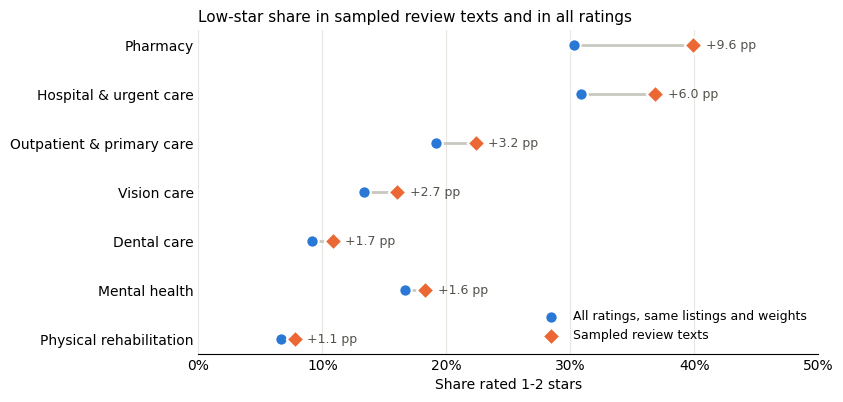

In [20]:
# Paired dots per service group, largest gap at the top.
chart_data = representation_table.drop(index="Overall").sort_values("Gap (pp)")
row_positions = np.arange(len(chart_data))
sampled_share = chart_data["Sampled-text low-star share"]
all_ratings_share = chart_data["All-ratings low-star share"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hlines(row_positions, all_ratings_share, sampled_share, color="#c9c8c0", linewidth=2, zorder=1)
ax.scatter(all_ratings_share, row_positions, s=80, color="#2a78d6", edgecolor="white", linewidth=1.5,
           zorder=2, label="All ratings, same listings and weights")
ax.scatter(sampled_share, row_positions, s=80, color="#eb6834", marker="D", edgecolor="white", linewidth=1.5,
           zorder=2, label="Sampled review texts")
for position, share, gap in zip(row_positions, np.maximum(sampled_share, all_ratings_share), chart_data["Gap (pp)"]):
    ax.annotate(f"{gap:+.1f} pp", (share, position), xytext=(9, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514b")

ax.set_yticks(row_positions, chart_data.index)
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel("Share rated 1-2 stars")
ax.set_title("Low-star share in sampled review texts and in all ratings", loc="left", fontsize=11)
ax.grid(axis="x", color="#e7e6e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
plt.show()

In every service group, the sampled texts hold a larger share of low-star reviews than all ratings at the same listings: 18.6% versus 15.6% overall, a gap of 2.9 percentage points. The gap is largest for pharmacies (39.9% versus 30.3%, 9.6 points), followed by hospitals and urgent care (6.0 points).

The comparison measures how the review sample we can read differs from the full rating record at the same listings. It says nothing about which services give better care. The full distribution includes ratings left without any text, and how and when `top_reviews` was selected and collected is not documented, so the gap cannot be assigned to one cause.

## 5. Text classification

This section trains a general-purpose classifier on the full Reviews file and locks it before any test set is scored. Review text is the only input. TF-IDF turns each review into weighted counts of its words and adjacent word pairs, with more weight on terms that are not common everywhere. Logistic regression then learns how strongly each term points toward or away from a low-star (1–2) label.

### Modeling sample

The source is every Reviews record with a 1–5 rating and nonblank text. To keep the healthcare cohort unseen, we first remove source records that share a `place_id` or a normalized text with it. Only the cohort's IDs and text keys are used for this step.

In [21]:
# Reload Reviews with the text. Section 2 kept only a has-text flag.
source_chunks = []
for chunk in pd.read_csv(REVIEWS_PATH, usecols=["place_id", "review_rating", "review"], chunksize=50_000):
    chunk_rating = pd.to_numeric(chunk["review_rating"], errors="coerce")
    chunk_has_text = chunk["review"].fillna("").astype(str).str.strip().ne("")
    source_chunks.append(chunk[chunk_rating.isin([1, 2, 3, 4, 5]) & chunk_has_text])
source_valid = pd.concat(source_chunks, ignore_index=True).rename(columns={"review_rating": "rating", "review": "text"})
source_valid["text"] = source_valid["text"].astype(str)
source_valid["low_star"] = source_valid["rating"] <= 2
source_valid["text_key"] = source_valid["text"].str.strip().str.casefold()

# Remove anything that overlaps the healthcare cohort by listing or by normalized text.
shares_cohort_place = source_valid["place_id"].isin(set(healthcare_reviews["place_id"]))
shares_cohort_text = source_valid["text_key"].isin(set(healthcare_reviews["text_key"]))
source_disjoint = source_valid[~shares_cohort_place & ~shares_cohort_text]

# Within a listing, keep one copy of a repeated text. If its copies disagree on the label, drop all of them.
source_unique = source_disjoint.drop_duplicates(["place_id", "text_key", "low_star"])
labels_per_text = source_unique.groupby(["place_id", "text_key"])["low_star"].transform("nunique")
source_reviews = source_unique[labels_per_text == 1].reset_index(drop=True)

Listings, not reviews, are split 60/20/20 into training, validation and internal test, so no listing appears in two partitions. Short reviews such as a two-word compliment recur across listings. Any text that also appears in training is removed from validation and test, and any text shared by validation and test is removed from test. The rule ignores labels.

In [22]:
source_place_ids = np.sort(source_reviews["place_id"].unique())
shuffled_place_ids = np.random.default_rng(RANDOM_STATE).permutation(source_place_ids)
n_train_places = round(0.6 * len(shuffled_place_ids))
n_validation_places = round(0.2 * len(shuffled_place_ids))
partition_by_place = {
    **dict.fromkeys(shuffled_place_ids[:n_train_places], "train"),
    **dict.fromkeys(shuffled_place_ids[n_train_places:n_train_places + n_validation_places], "validation"),
    **dict.fromkeys(shuffled_place_ids[n_train_places + n_validation_places:], "test"),
}
source_reviews["partition"] = source_reviews["place_id"].map(partition_by_place)

# Identical text across partitions: training keeps it, then validation has priority over test.
train_text_keys = set(source_reviews.loc[source_reviews["partition"] == "train", "text_key"])
validation_text_keys = set(source_reviews.loc[source_reviews["partition"] == "validation", "text_key"])
repeats_earlier_partition = (
    (source_reviews["partition"].eq("validation") & source_reviews["text_key"].isin(train_text_keys))
    | (source_reviews["partition"].eq("test") & source_reviews["text_key"].isin(train_text_keys | validation_text_keys))
)
modeling_reviews = source_reviews[~repeats_earlier_partition].reset_index(drop=True)

train_reviews = modeling_reviews[modeling_reviews["partition"] == "train"]
validation_reviews = modeling_reviews[modeling_reviews["partition"] == "validation"]
internal_test_reviews = modeling_reviews[modeling_reviews["partition"] == "test"]

In [23]:
def format_columns(table, formats):
    """Return a display copy of a table with a number format applied to each listed column."""
    return table.assign(**{
        column: table[column].map(lambda value, fmt=fmt: "undefined" if pd.isna(value) else fmt.format(value))
        for column, fmt in formats.items()
    })


def sample_row(label, frame):
    return {
        "Stage or partition": label,
        "Reviews": len(frame),
        "Listings": frame["place_id"].nunique(),
        "Low-star reviews": int(frame["low_star"].sum()),
        "Low-star share": frame["low_star"].mean(),
    }


modeling_table = pd.DataFrame([
    sample_row("Reviews with a 1-5 rating and text", source_valid),
    sample_row("No listing or text shared with the cohort", source_disjoint),
    sample_row("One copy per listing and text", source_reviews),
    sample_row("No text shared across partitions", modeling_reviews),
    sample_row("Training", train_reviews),
    sample_row("Validation", validation_reviews),
    sample_row("Internal test", internal_test_reviews),
])
format_columns(modeling_table, {
    "Reviews": "{:,}", "Listings": "{:,}", "Low-star reviews": "{:,}", "Low-star share": "{:.1%}",
})

,Stage or partition,Reviews,Listings,Low-star reviews,Low-star share
0,Reviews with a 1-5 rating and text,"171,344","6,103","30,693",17.9%
1,No listing or text shared with the cohort,"167,434","5,986","30,036",17.9%
2,One copy per listing and text,"167,347","5,986","30,029",17.9%
3,No text shared across partitions,"166,790","5,979","29,993",18.0%
4,Training,"100,760","3,592","17,999",17.9%
5,Validation,"32,697","1,194","5,776",17.7%
6,Internal test,"33,333","1,193","6,218",18.7%


In [24]:
# Leakage checks before any fitting.
partitions = [train_reviews, validation_reviews, internal_test_reviews]
for first, second in [(0, 1), (0, 2), (1, 2)]:
    assert not set(partitions[first]["place_id"]) & set(partitions[second]["place_id"])
    assert not set(partitions[first]["text_key"]) & set(partitions[second]["text_key"])
assert all(frame["low_star"].nunique() == 2 for frame in partitions)
assert not set(modeling_reviews["place_id"]) & set(healthcare_reviews["place_id"])
assert not set(modeling_reviews["text_key"]) & set(healthcare_reviews["text_key"])
assert not modeling_reviews.duplicated(["place_id", "text_key"]).any()

print(f"Removed for sharing a cohort listing: {shares_cohort_place.sum():,}; a cohort text: {shares_cohort_text.sum():,}; either: {(shares_cohort_place | shares_cohort_text).sum():,}")
print(f"Same-listing repeats removed: {len(source_disjoint) - len(source_unique):,}; rows in label-conflict sets removed: {len(source_unique) - len(source_reviews):,}")
print("Rows removed for repeating a text from an earlier partition:",
      source_reviews.loc[repeats_earlier_partition, "partition"].value_counts().to_dict())

Removed for sharing a cohort listing: 2,612; a cohort text: 1,398; either: 3,910
Same-listing repeats removed: 87; rows in label-conflict sets removed: 0
Rows removed for repeating a text from an earlier partition: {'test': 309, 'validation': 248}


Removing overlap with the healthcare cohort took out 3,910 source reviews: 2,612 from shared listings and 1,398 with a shared text, 100 of them both. Within listings, 87 repeated texts were dropped, and no repeated text carried conflicting labels. The cross-partition rule then removed 248 validation rows and 309 test rows.

The split is by listing, so review shares can drift from 60/20/20. Here they stayed close: 60.4%, 19.6% and 20.0% of the 166,790 modeling reviews, with a low-star share near 18% in each partition.

### Model selection

The baseline always predicts the most common training label. The main model is a TF-IDF and logistic regression pipeline, so the vocabulary is learned only from the data the pipeline is fitted on. No stop-word list is used, which keeps negations such as "not" and "never". A review is called low-star when its predicted probability is at least 0.5. That threshold is fixed and is never tuned.

Four settings are compared on validation macro-F1: `C` of 0.5 or 2.0 (smaller means stronger regularization), with or without balanced class weights. An exact tie goes to `C = 0.5`, then to the unweighted model.

In [25]:
LOW_STAR_THRESHOLD = 0.5
CANDIDATE_SETTINGS = [(0.5, None), (0.5, "balanced"), (2.0, None), (2.0, "balanced")]  # in tie-break order


def make_text_model(C, class_weight):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000)),
        ("classifier", LogisticRegression(C=C, class_weight=class_weight, max_iter=2000)),
    ])


def fit_checked(model, frame):
    """Fit on a frame of reviews and raise if the solver stops before converging."""
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        return model.fit(frame["text"], frame["low_star"].astype(int))


def predict_low_star(model, frame):
    return (model.predict_proba(frame["text"])[:, 1] >= LOW_STAR_THRESHOLD).astype(int)


def score_predictions(actual_low_star, predicted_low_star):
    """Metrics with low-star (1) as the positive class. Precision is undefined when nothing is predicted low-star."""
    tn, fp, fn, tp = confusion_matrix(actual_low_star.astype(int), predicted_low_star, labels=[0, 1]).ravel()
    return {
        "Reviews": tn + fp + fn + tp,
        "Actual low-star": tp + fn,
        "Macro-F1": f1_score(actual_low_star.astype(int), predicted_low_star, labels=[0, 1], average="macro", zero_division=0),
        "Low-star precision": tp / (tp + fp) if tp + fp else np.nan,
        "Low-star recall": tp / (tp + fn),
        "Low-star F1": 2 * tp / (2 * tp + fp + fn),
        "Missed low-star": fn,
        "False positives": fp,
    }

In [26]:
METRIC_FORMATS = {"Macro-F1": "{:.3f}", "Low-star precision": "{:.3f}", "Low-star recall": "{:.3f}", "Low-star F1": "{:.3f}"}

validation_rows = []
for C, class_weight in CANDIDATE_SETTINGS:
    candidate = fit_checked(make_text_model(C, class_weight), train_reviews)
    scores = score_predictions(validation_reviews["low_star"], predict_low_star(candidate, validation_reviews))
    validation_rows.append({"C": C, "class_weight": str(class_weight), **{metric: scores[metric] for metric in METRIC_FORMATS}})
validation_table = pd.DataFrame(validation_rows)

# idxmax returns the first maximum, and the settings are listed in tie-break order.
SELECTED_C, SELECTED_CLASS_WEIGHT = CANDIDATE_SETTINGS[validation_table["Macro-F1"].idxmax()]
print(f"Selected: C = {SELECTED_C}, class_weight = {SELECTED_CLASS_WEIGHT}")
format_columns(validation_table, METRIC_FORMATS)

.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 

Selected: C = 2.0, class_weight = None


,C,class_weight,Macro-F1,Low-star precision,Low-star recall,Low-star F1
0,0.5,None,0.890,0.874,0.765,0.816
1,0.5,balanced,0.888,0.728,0.941,0.821
2,2.0,None,0.905,0.869,0.818,0.843
3,2.0,balanced,0.896,0.751,0.937,0.834


`C = 2.0` without class weights had the highest validation macro-F1 (0.905) and is the selected setting. Balanced class weights caught more low-star reviews (recall near 0.94) but with clearly lower precision (0.73 to 0.75). All four fits converged; a convergence warning would have stopped the cell.

In [27]:
# Refit the selected settings and the baseline on training + validation. Both are now locked.
train_validation_reviews = pd.concat([train_reviews, validation_reviews])
final_model = fit_checked(make_text_model(SELECTED_C, SELECTED_CLASS_WEIGHT), train_validation_reviews)
baseline_model = DummyClassifier(strategy="most_frequent").fit(
    train_validation_reviews["text"], train_validation_reviews["low_star"].astype(int)
)

# Internal test: general Google Maps reviews from listings the model has not seen.
internal_test_scores = {
    "Majority baseline": score_predictions(internal_test_reviews["low_star"], predict_low_star(baseline_model, internal_test_reviews)),
    "TF-IDF + logistic regression": score_predictions(internal_test_reviews["low_star"], predict_low_star(final_model, internal_test_reviews)),
}

.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)


The internal test results are shown once, in Section 6, next to the healthcare results.

## 6. Where does the model miss low-star reviews?

The locked model and baseline now score the Bay Area healthcare cohort from Section 3. Nothing is refitted, reselected or re-thresholded here. The cohort's labels were used for the descriptive work in Sections 3 and 4, but not for any modeling decision.

In [28]:
healthcare_scored = healthcare_reviews.assign(
    actual_low_star=healthcare_reviews["low_star"].astype(int),
    predicted_low_star=predict_low_star(final_model, healthcare_reviews),
    low_star_probability=final_model.predict_proba(healthcare_reviews["text"])[:, 1],
)
healthcare_scores = {
    "Majority baseline": score_predictions(healthcare_reviews["low_star"], predict_low_star(baseline_model, healthcare_reviews)),
    "TF-IDF + logistic regression": score_predictions(healthcare_scored["actual_low_star"], healthcare_scored["predicted_low_star"]),
}

overall_table = pd.DataFrame({
    ("Internal test: general reviews", classifier): scores for classifier, scores in internal_test_scores.items()
} | {
    ("External test: Bay Area healthcare", classifier): scores for classifier, scores in healthcare_scores.items()
}).T.rename_axis(["Test set", "Classifier"]).drop(columns="False positives")
format_columns(overall_table, {"Reviews": "{:,.0f}", "Actual low-star": "{:,.0f}", "Missed low-star": "{:,.0f}", **METRIC_FORMATS})

Reviews  \
Test set                           Classifier                             
Internal test: general reviews     Majority baseline             33,333   
                                   TF-IDF + logistic regression  33,333   
External test: Bay Area healthcare Majority baseline             68,007   
                                   TF-IDF + logistic regression  68,007   

                                                                Actual low-star  \
Test set                           Classifier                                     
Internal test: general reviews     Majority baseline                      6,218   
                                   TF-IDF + logistic regression           6,218   
External test: Bay Area healthcare Majority baseline                     12,617   
                                   TF-IDF + logistic regression          12,617   

                                                                Macro-F1  \
Test set                           Classifier                              
Internal test: general reviews     Majority baseline               0.449   
                                   TF-IDF + logistic regression    0.910   
External test: Bay Area healthcare Majority baseline               0.449   
                                   TF-IDF + logistic regression    0.927   

                                                                Low-star precision  \
Test set                           Classifier                                        
Internal test: general reviews     Majority baseline                     undefined   
                                   TF-IDF + logistic regression              0.880   
External test: Bay Area healthcare Majority baseline                     undefined   
                                   TF-IDF + logistic regression              0.947   

                                                                Low-star recall  \
Test set                           Classifier                                     
Internal test: general reviews     Majority baseline                      0.000   
                                   TF-IDF + logistic regression           0.826   
External test: Bay Area healthcare Majority baseline                      0.000   
                                   TF-IDF + logistic regression           0.819   

                                                                Low-star F1  \
Test set                           Classifier                                 
Internal test: general reviews     Majority baseline                  0.000   
                                   TF-IDF + logistic regression       0.852   
External test: Bay Area healthcare Majority baseline                  0.000   
                                   TF-IDF + logistic regression       0.878   

                                                                Missed low-star  
Test set                           Classifier                                    
Internal test: general reviews     Majority baseline                      6,218  
                                   TF-IDF + logistic regression           1,085  
External test: Bay Area healthcare Majority baseline                     12,617  
                                   TF-IDF + logistic regression           2,278

The baseline never predicts low-star. It misses every low-star review, so its recall and F1 are 0, and its precision is undefined because it makes no low-star predictions. Its macro-F1 of 0.449 comes entirely from the "other" class.

On the healthcare cohort the model reaches a macro-F1 of 0.927, with low-star precision 0.947 and recall 0.819. It misses 2,278 of 12,617 low-star reviews, about 18 in every 100. Recall on the internal test is similar (0.826, with 1,085 of 6,218 missed). The two test sets differ in domain, in how reviews were selected and in label mix, so small differences between them should not be over-read.

In [29]:
def group_error_row(frame):
    scores = score_predictions(frame["actual_low_star"], frame["predicted_low_star"])
    return {
        "Reviews": scores["Reviews"],
        "Listings": frame["place_id"].nunique(),
        "Actual low-star": scores["Actual low-star"],
        "Missed (false negatives)": scores["Missed low-star"],
        "False positives": scores["False positives"],
        "Low-star precision": scores["Low-star precision"],
        "Low-star recall": scores["Low-star recall"],
        "Miss rate": scores["Missed low-star"] / scores["Actual low-star"],
    }


group_error_table = pd.DataFrame(
    {group: group_error_row(frame) for group, frame in healthcare_scored.groupby("service_group")}
).T.reindex(list(SERVICE_GROUPS)).rename_axis("Service group")

# Group rows must add up to the overall external result. Overall recall pools the groups; it is not their average.
external_model_scores = healthcare_scores["TF-IDF + logistic regression"]
assert group_error_table["Reviews"].sum() == external_model_scores["Reviews"]
assert group_error_table["Actual low-star"].sum() == external_model_scores["Actual low-star"]
assert group_error_table["Missed (false negatives)"].sum() == external_model_scores["Missed low-star"]
assert group_error_table["False positives"].sum() == external_model_scores["False positives"]
pooled_true_positives = (group_error_table["Actual low-star"] - group_error_table["Missed (false negatives)"]).sum()
assert np.isclose(pooled_true_positives / group_error_table["Actual low-star"].sum(), external_model_scores["Low-star recall"])

format_columns(group_error_table, {
    "Reviews": "{:,.0f}", "Listings": "{:,.0f}", "Actual low-star": "{:,.0f}",
    "Missed (false negatives)": "{:,.0f}", "False positives": "{:,.0f}",
    "Low-star precision": "{:.3f}", "Low-star recall": "{:.3f}", "Miss rate": "{:.1%}",
})

,Reviews,Listings,Actual low-star,Missed (false negatives),False positives,Low-star precision,Low-star recall,Miss rate
Service group,,,,,,,,
Outpatient & primary care,"21,063","6,277","4,716",898,174,0.956,0.810,19.0%
Dental care,"22,480","5,636","2,440",418,115,0.946,0.829,17.1%
Mental health,"9,523","2,913","1,743",385,62,0.956,0.779,22.1%
Pharmacy,"4,762","1,087","1,900",297,137,0.921,0.844,15.6%
Hospital & urgent care,"2,020",450,744,114,35,0.947,0.847,15.3%
Vision care,"5,306","1,306",852,120,41,0.947,0.859,14.1%
Physical rehabilitation,"2,853",747,222,46,19,0.903,0.793,20.7%


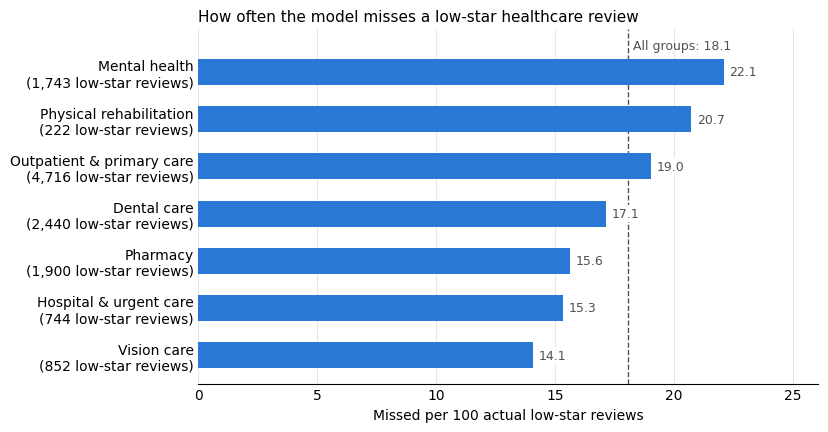

In [30]:
# Missed reviews per 100 actual low-star reviews, highest at the top. Labels carry the low-star denominator.
miss_chart = group_error_table.sort_values("Miss rate")
missed_per_100 = 100 * miss_chart["Miss rate"]
overall_missed_per_100 = 100 * (1 - external_model_scores["Low-star recall"])
bar_labels = [f"{group}\n({count:,.0f} low-star reviews)" for group, count in miss_chart["Actual low-star"].items()]

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.barh(bar_labels, missed_per_100, height=0.55, color="#2a78d6", zorder=2)
ax.axvline(overall_missed_per_100, color="#52514b", linewidth=1, linestyle="--", zorder=1)
ax.bar_label(bars, labels=[f"{value:.1f}" for value in missed_per_100], padding=4, fontsize=9, color="#52514b",
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
ax.annotate(f"All groups: {overall_missed_per_100:.1f}", (overall_missed_per_100, len(bar_labels) - 0.45),
            xytext=(4, 0), textcoords="offset points", fontsize=9, color="#52514b", va="center")

ax.set_xlim(0, max(missed_per_100) * 1.18)
ax.set_ylim(-0.6, len(bar_labels) - 0.1)
ax.set_xlabel("Missed per 100 actual low-star reviews")
ax.set_title("How often the model misses a low-star healthcare review", loc="left", fontsize=11)
ax.grid(axis="x", color="#e7e6e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.show()

Miss rates run from 14.1 per 100 low-star reviews in vision care (120 of 852) to 22.1 per 100 in mental health (385 of 1,743). Mental health has the highest rate. Outpatient and primary care has the most missed reviews (898 of 4,716, or 19.0 per 100), because it holds the most low-star reviews. The physical rehabilitation rate of 20.7 has the smallest low-star denominator (222).

Pharmacies and hospitals, where Section 4 found the largest sampling gaps, are not where the model misses most often (15.6 and 15.3 per 100). These are differences in model reliability across service settings in the observed reviews, not effects caused by the type of service.

### Reading the errors

After the predictions were fixed, we drew a seeded sample of 10 missed low-star reviews and 10 false positives: two of each from outpatient and primary care, pharmacy and mental health, and one of each from the other four groups. The texts were read locally and are not printed here.

In [31]:
ERROR_SAMPLE_SIZES = {group: 2 if group in ("Outpatient & primary care", "Pharmacy", "Mental health") else 1 for group in SERVICE_GROUPS}


def sample_errors(errors, error_type):
    sampled = [
        errors[errors["service_group"] == group].sample(n=size, random_state=RANDOM_STATE)
        for group, size in ERROR_SAMPLE_SIZES.items()
    ]
    return pd.concat(sampled).assign(error_type=error_type)


is_missed = (healthcare_scored["actual_low_star"] == 1) & (healthcare_scored["predicted_low_star"] == 0)
is_false_positive = (healthcare_scored["actual_low_star"] == 0) & (healthcare_scored["predicted_low_star"] == 1)
error_sample = pd.concat([
    sample_errors(healthcare_scored[is_missed], "missed low-star"),
    sample_errors(healthcare_scored[is_false_positive], "false positive"),
])[["error_type", "service_group", "rating", "low_star_probability", "text"]]
print(error_sample["error_type"].value_counts().to_dict())

{'missed low-star': 10, 'false positive': 10}


Three patterns recurred in the 20 sampled errors. They illustrate how the model fails. The sample is too small to say how common each pattern is in the cohort.

- **Problems described plainly.** Several missed reviews reported a problem in calm, factual language, with few of the complaint words that are common in general reviews.
- **Praise and criticism together.** Some missed reviews praised one clinician while complaining about someone else, such as front-desk staff or a referral. The reverse also occurred: positive reviews that criticized a previous provider were flagged as low-star.
- **Text and stars that disagree.** Several false positives were 3- or 4-star reviews whose text was mostly a complaint. In these cases the star label is arguably the weaker signal.

Anonymous paraphrases of three inspected errors:

- *Missed low-star, outpatient and primary care, 1 star.* In a single sentence, the reviewer reports that a diagnosis was wrong and that serious consequences followed. The problem is stated as a fact, with almost no evaluative wording.
- *Missed low-star, vision care, 1 star.* The reviewer calls the doctor great but describes the front-desk staff as unhelpful. Praise and complaint share one short text.
- *False positive, pharmacy, 4 stars.* The reviewer reports that advertised opening hours were no longer offered and calls this unprofessional. The text reads as a complaint, so the case is ambiguous: it may say more about the star label than about the model.

Reading a review shows what made its text hard to classify. It does not show why the model produced a particular prediction.

## 7. Limits and implications

**Which feedback reaches the sample we can read?** At the same listings and weights, 18.6% of sampled review texts were low-star, against 15.6% of all ratings, a gap of 2.9 percentage points. The gap appeared in all seven service groups and was largest for pharmacies (9.6 points). Anyone reading or modeling these texts sees a larger share of dissatisfaction than the full rating record holds.

**Which low-star feedback does a general model miss?** A classifier trained only on general Google Maps reviews transferred well to healthcare. On 68,007 healthcare reviews its low-star precision was 0.947 and its recall 0.819, where the majority baseline finds no low-star review at all. It still missed 2,278 of 12,617 low-star reviews, and the miss rate ran from about 14 per 100 in vision care to 22 per 100 in mental health. Some of the missed reviews we read described problems in neutral language, and some mixed a complaint with praise for someone else.

**For a service organization.** A model like this could sort incoming written feedback for human review, but it should not be the only route by which a complaint gets seen. About 18 of every 100 low-star reviews would be filed as "other", more in some services than in others. Checking miss rates by service before relying on such a tool, and sampling the "other" pile by hand, would address both points.

**Limits**

- Star ratings are a proxy for expressed dissatisfaction. Some 3- and 4-star reviews contain real complaints, so part of the measured error is disagreement between text and stars.
- Serving a community, receiving a Google review, appearing in `top_reviews` and receiving a model prediction are separate stages. These data only cover reviews that reached `top_reviews`, and people who never post are absent.
- The selection and collection timing of `top_reviews` are undocumented, so the Section 4 gap cannot be assigned to one cause.
- Service groups follow Google's primary category, and a listing can be a practitioner, a department or a facility. Group differences describe how reliable the model is on these observed reviews. They do not measure clinical quality or demographic discrimination, and the data hold no demographic information.
- The model was evaluated at one fixed threshold, and the error reading covered 20 reviews.
- Exact error counts can differ between computing setups. An independent run on a different setup reported 2,136 missed reviews and 605 false positives, against 2,278 and 583 in the saved run, with the same healthcare cohort and selected settings. The saved counts repeated exactly in fresh runs in the environment listed in the README.